# BRASA · Evaluación y generalización

Revisar el resultado con una configuración común evita parámetros específicos por escena. Las tres escenas disponibles son **desarrollo**, no validación independiente. Este cuaderno presenta el informe reproducible guardado por `python backend/evaluate.py --robustness` y muestra los pasos de interpretación. Las perturbaciones miden consistencia, nunca exactitud.

Para medir precisión hay que aportar máscaras manuales independientes, incluyendo escenas sin incendio y nuevos incidentes reservados como `holdout`. Wildfires no es verdad terreno.

In [1]:
%matplotlib inline
from pathlib import Path
import json, sys
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
BACKEND = Path.cwd().resolve()
if (BACKEND / "backend").is_dir():
    BACKEND = BACKEND / "backend"
sys.path.insert(0, str(BACKEND))
report_path = BACKEND / "evaluation" / "latest" / "report.json"
if not report_path.exists():
    from evaluate import run
    run(BACKEND / "evaluation" / "manifest.json", report_path.parent, robustness=True)
report = json.loads(report_path.read_text(encoding="utf-8"))
print("Algoritmo:", report["algorithm"])
print("Configuración común:", json.dumps(report["config"], indent=2))
print("Huella del manifiesto:", report["manifest_sha256"])
display(Markdown((report_path.parent / "report.md").read_text(encoding="utf-8")))

Algoritmo: colour-hysteresis+rgb-context-v2
Configuración común: {
  "max_side": 1536,
  "sensitivity": 0.5,
  "min_area_fraction": 0.00012,
  "closing_radius": 2,
  "max_hole_fraction": 0.00015,
  "simplify_pixels": 1.5,
  "refine": true,
  "pixel_size_m": 20
}
Huella del manifiesto: b25fdb53973227f5dd1bdcabee198abcecfbd65a028790ce0e110ba3682f8ea2


# Evaluación reproducible

La estabilidad mide consistencia ante perturbaciones, no precisión. Sin referencias independientes no se mide generalización.

Escala declarada: 20 m/píxel original; se compensa el remuestreo. Área y perímetro son estimados.

| Escena | Partición | Regiones | Área ha | Perímetro km | Focos sin/con contexto | Referencias |
|---|---|---:|---:|---:|---|---|
| niebla | development | 11 | 7148.4 | 212.1 | 44/36 | affected: not_provided, active: not_provided |
| la-mierla | development | 14 | 14424.8 | 340.6 | 195/65 | affected: not_provided, active: not_provided |
| madrid-avila | development | 16 | 93995.2 | 1176.9 | 388/207 | affected: not_provided, active: not_provided |

## Estabilidad (IoU respecto al resultado original, no exactitud)

| Escena | Perturbación | Cicatriz | Focos |
|---|---|---:|---:|
| niebla | brightness_0.9 | 0.988 | 0.940 |
| niebla | brightness_1.1 | 0.992 | 0.778 |
| niebla | jpeg_quality_70 | 0.928 | 0.759 |
| niebla | scale_075 | 0.966 | 0.844 |
| la-mierla | brightness_0.9 | 0.995 | 0.798 |
| la-mierla | brightness_1.1 | 0.995 | 0.882 |
| la-mierla | jpeg_quality_70 | 0.930 | 0.609 |
| la-mierla | scale_075 | 0.964 | 0.755 |
| madrid-avila | brightness_0.9 | 0.992 | 0.414 |
| madrid-avila | brightness_1.1 | 0.987 | 0.555 |
| madrid-avila | jpeg_quality_70 | 0.893 | 0.511 |
| madrid-avila | scale_075 | 0.969 | 0.887 |

Los pares con ambas máscaras vacías tienen estabilidad 1; no acreditan detección correcta.
Las escenas de desarrollo no son un conjunto de validación independiente. Mantener umbrales fijos y separar incidentes nuevos como holdout antes de observar sus resultados.
El humo puede ocultar focos. El contraste local puede perder frentes extensos. Suelo rojo y superficies urbanas pueden seguir generando candidatos.
La exactitud se calcula solo cuando el manifiesto incluye referencias manuales independientes; Wildfires no es una referencia cuantitativa.
Revisar estabilidad en madrid-avila (IoU < 0,6): brightness_0.9/active, brightness_1.1/active, jpeg_quality_70/active.


## 1. Resultados visuales con los mismos parámetros

Naranja: evidencia de afectación. Magenta: posible fuego activo. Humo, suelo rojo y pequeñas detecciones aisladas requieren revisión. Las medidas usan 20 m por píxel original, compensando el tamaño final de máscara.

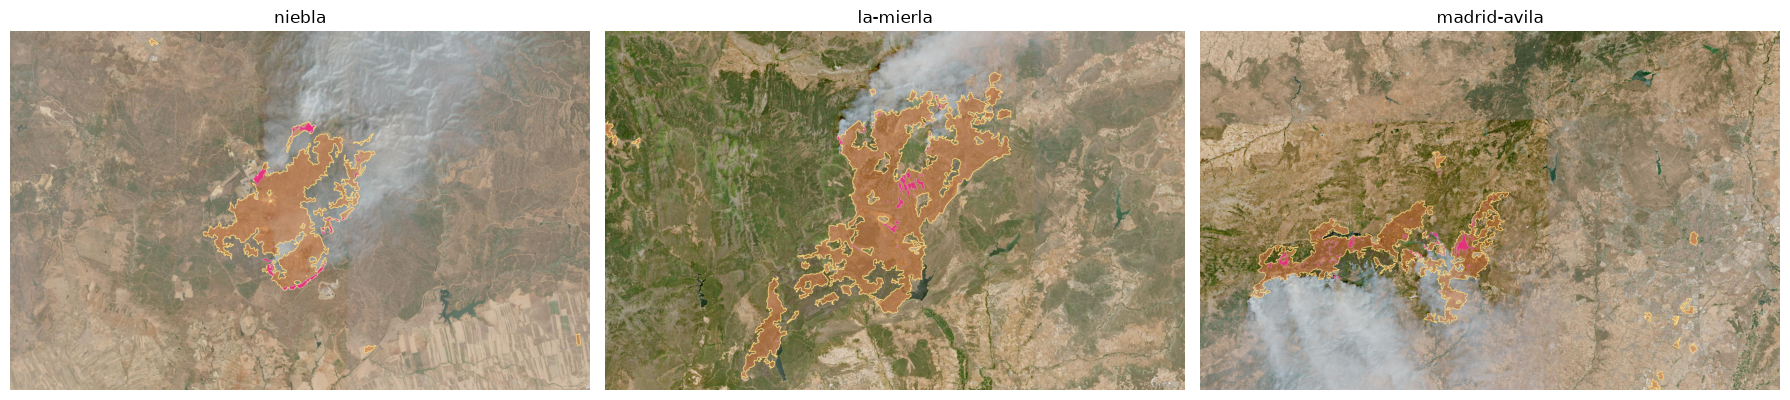

In [2]:
fig, axes = plt.subplots(1, len(report["scenes"]), figsize=(18, 6), squeeze=False)
for i, row in enumerate(report["scenes"]):
    axes[0, i].imshow(Image.open(report_path.parent / f"scene_{i+1}_overlay.jpg"))
    axes[0, i].set_title(row["id"])
    axes[0, i].axis("off")
plt.tight_layout()
plt.show()

## 2. Estabilidad frente a brillo, JPEG y reducción de tamaño

Se comparan las máscaras perturbadas con la salida original. IoU alta significa consistencia del algoritmo; podría ser consistentemente erróneo. Dos máscaras vacías reciben estabilidad 1. Los focos pequeños son más sensibles a cuantización y brillo.

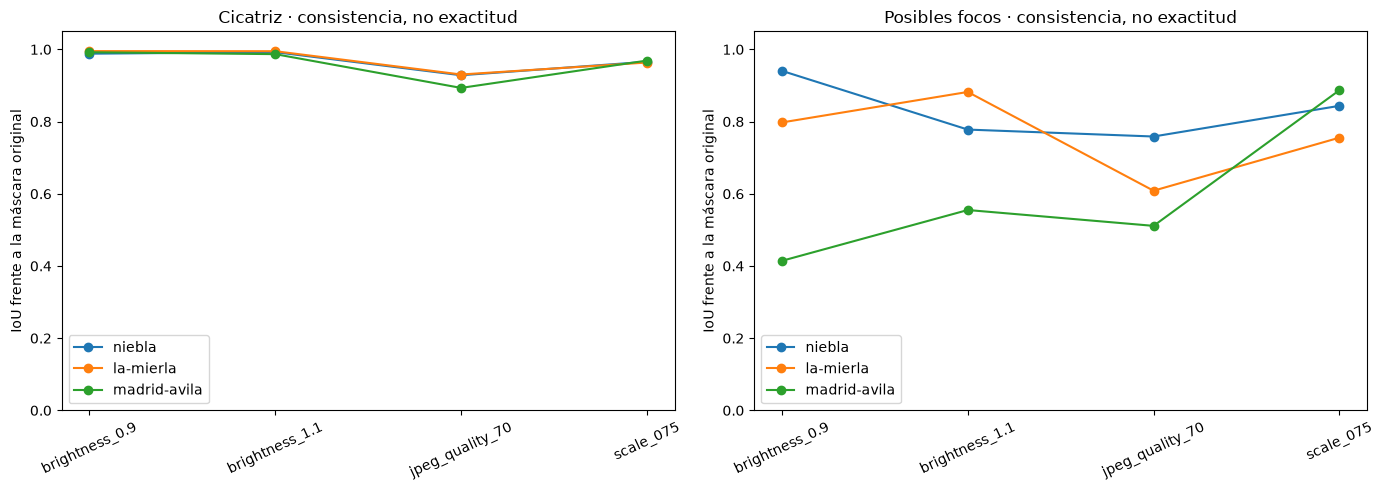

niebla revisar: []
la-mierla revisar: []
madrid-avila revisar: ['brightness_0.9/active', 'brightness_1.1/active', 'jpeg_quality_70/active']


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for row in report["scenes"]:
    names = list(row["stability"])
    for ax, layer in zip(axes, ["affected", "active"]):
        ax.plot(names, [row["stability"][name][layer]["iou_self_consistency"] for name in names], marker="o", label=row["id"])
for ax, title in zip(axes, ["Cicatriz", "Posibles focos"]):
    ax.set_title(title + " · consistencia, no exactitud")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("IoU frente a la máscara original")
    ax.legend()
plt.tight_layout()
plt.show()
for row in report["scenes"]:
    print(row["id"], "revisar:", row.get("stability_review", []))

## 3. Exactitud y falsos positivos con referencias independientes

El manifiesto admite `references: {"affected": {"path": "...png", "grid": "original"}, "active": {"path": "...png", "grid": "analysis"}}`. Cada máscara es de un canal: 0=fondo, 1=objetivo, 255=ignorar. Una referencia `original` se remuestrea por vecino más cercano a la cuadrícula de análisis; esa operación queda registrada. Incluir referencias de fondo en escenas negativas permite medir falsos positivos.

Se calculan IoU, Dice, precisión, recall y F1 de contorno (tolerancia de 2 píxeles de análisis). Para focos se añade correspondencia uno a uno de componentes con IoU mínimo 0,1. Las métricas indefinidas quedan como `null`.

Reservar incidentes completos como `holdout` antes de inspeccionar resultados; congelar código, configuración y hashes. Reportar por incidente y por clase, revisando falsos positivos en agua, vegetación, suelo desnudo, zonas urbanas y nubes/humo. No ajustar umbrales mirando el holdout.

In [4]:
for row in report["scenes"]:
    print(row["id"], row["split"])
    print(json.dumps(row["metrics"], ensure_ascii=False, indent=2))
print("Sin referencias no se puede certificar exactitud ni generalización.")

niebla development
{
  "affected": {
    "status": "not_provided",
    "pixel": null,
    "components": null
  },
  "active": {
    "status": "not_provided",
    "pixel": null,
    "components": null
  }
}
la-mierla development
{
  "affected": {
    "status": "not_provided",
    "pixel": null,
    "components": null
  },
  "active": {
    "status": "not_provided",
    "pixel": null,
    "components": null
  }
}
madrid-avila development
{
  "affected": {
    "status": "not_provided",
    "pixel": null,
    "components": null
  },
  "active": {
    "status": "not_provided",
    "pixel": null,
    "components": null
  }
}
Sin referencias no se puede certificar exactitud ni generalización.
